# TPOT classifier experiment

This experiment uses the same group-aware holdout and shared TF-IDF features as the logistic-regression analysis. TPOT searches linear-model pipelines using training data only; the held-out report and confusion matrix are used for comparison. Small per-class support makes these results exploratory.

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, str(Path.cwd()))

from data import load_data, make_groups
from evaluation import baseline_predictions, evaluate, split_data
from model import build_vectorizer

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

majority_label, baseline = baseline_predictions(train["label"], len(test))
print(f"majority baseline: {majority_label}")
display(
    pd.DataFrame(evaluate(test["label"], baseline, labels)["report"])
    .T[["precision", "recall", "f1-score", "support"]]
    .round(3)
)

vectorizer = build_vectorizer()
X_train = vectorizer.fit_transform(train["headline"])
X_test = vectorizer.transform(test["headline"])
print(f"TF-IDF train: {X_train.shape}; test: {X_test.shape}")

majority baseline: vilifying_opponents


,precision,recall,f1-score,support
nothing,0.000,0.000,0.000,22.000
personality_cult,0.000,0.000,0.000,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.000,0.000,0.000,20.000
vilifying_opponents,0.538,1.000,0.700,71.000
accuracy,0.538,0.538,0.538,0.538
macro avg,0.108,0.200,0.140,132.000
weighted avg,0.289,0.538,0.376,132.000


TF-IDF train: (323, 7339); test: (132, 7339)


In [8]:
from tpot import TPOTClassifier

est = TPOTClassifier(
    search_space="linear",
    scorers=["balanced_accuracy"],
    cv=3,
    n_jobs=5,
    max_time_mins=15,
    max_eval_time_mins=5,
    verbose=2
)
est.fit(X_train, train["label"])
print(est.fitted_pipeline_)

/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 54206 instead
  warnings.warn(
/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/tpot/tpot_estimator/estimator.py:537: UserWarning: Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklearn, TPOT has encoded y with the sklearn LabelEncoder. When using pipelines outside the main TPOT estimator class, you can encode the labels with est.label_encoder_
  warnings.warn("Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklearn, TPOT has encoded y with the sklearn LabelEncoder. When using pipelines outside the main TPOT estimator class, you can encode the labels with est.label_encoder_")
Generation: : 0it [00:00, ?it/s]/Users/jtakalai/python/propaga

Pipeline(steps=[('normalizer', Normalizer(norm=np.str_('max'))),
                ('variancethreshold',
                 VarianceThreshold(threshold=0.0001498036177)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('featureunion',
                                                 FeatureUnion(transformer_list=[('nystroem',
                                                                                 Nystroem(gamma=0.4572786422476,
                                                                                          kernel=np.str_('linear'),
                                                                                          n_components=6885))])),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransform

Accuracy: TPOT 0.667 | majority baseline 0.538


,precision,recall,f1-score,support
nothing,0.800,0.364,0.500,22.000
personality_cult,0.462,0.857,0.600,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.750,0.750,0.750,20.000
vilifying_opponents,0.756,0.831,0.792,71.000
accuracy,0.667,0.667,0.667,0.667
macro avg,0.554,0.560,0.528,132.000
weighted avg,0.678,0.667,0.655,132.000


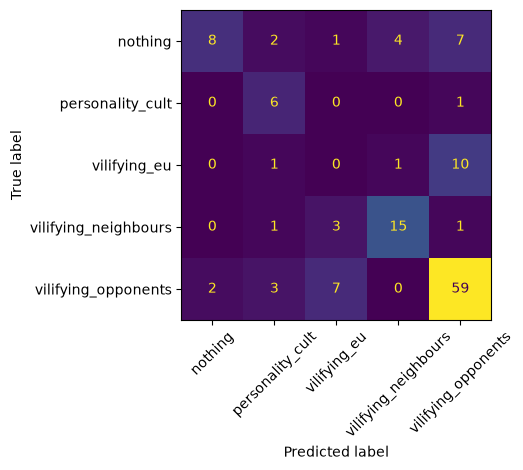

In [9]:
encoded_predictions = est.predict(X_test).astype(int)
predictions = est.label_encoder_.inverse_transform(encoded_predictions)
metrics = evaluate(test["label"], predictions, labels)
baseline_accuracy = evaluate(test["label"], baseline, labels)["report"]["accuracy"]
print(
    f"Accuracy: TPOT {metrics['report']['accuracy']:.3f} "
    f"| majority baseline {baseline_accuracy:.3f}"
)
display(
    pd.DataFrame(metrics["report"]).T[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

ConfusionMatrixDisplay(
    metrics["confusion_matrix"],
    display_labels=labels,
).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()